# Shoplifting Detection: Fine-tuning a Pretrained Video Model

VideoMAE (Kinetics-400) fine-tuned for normal vs shoplifting classification, compared against the Week 5 scratch CNN + BiLSTM.

In [1]:
import os, glob, time, math, random, warnings
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
from transformers import VideoMAEForVideoClassification

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
print(device, torch.cuda.get_device_name(0) if use_cuda else "")

cuda Tesla T4


In [2]:
DATA_URL = "https://drive.google.com/file/d/1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-/view?usp=sharing"
MODEL_NAME = "MCG-NJU/videomae-base-finetuned-kinetics"
IMG = 224
CACHE_N = 48
T_DEFAULT = 16
CAND_THR = 0.60    # centred video-level cosine: only pairs above this are examined further
DUP_THR = 0.90     # mean aligned frame-by-frame cosine >= this -> duplicate, dropped (one copy kept)
GROUP_THR = 0.80   # >= this -> same group, kept in the same split (prevents leakage)
MAX_DROP = 0.30    # safety stop: refuse to drop more than this fraction of clips
RUN_CV = False     # grouped k-fold CV on the final recipe (slow, ~5x training time)
CV_FOLDS, CV_EPOCHS = 5, 6
RUN_SWEEP = True
SWEEP_T = (8, 16, 32)
SWEEP_EPOCHS = 2
EPOCHS = 10
PATIENCE = 3
LR_BODY, LR_HEAD = 3e-5, 3e-4

WORK = "/kaggle/working"
CACHE_DIR = f"{WORK}/cache"
os.makedirs(CACHE_DIR, exist_ok=True)

if DATA_URL.startswith("http"):
    os.system(f'pip -q install gdown && gdown --fuzzy "{DATA_URL}" -O {WORK}/data.zip')
    os.system(f"unzip -q -o {WORK}/data.zip -d {WORK}/data")
    ROOT = f"{WORK}/data"
else:
    ROOT = "/kaggle/input"

Downloading...
From (original): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-
From (redirected): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-&confirm=t&uuid=cc818f67-de8e-4436-a30e-af93806342cf
To: /kaggle/working/data.zip
100%|██████████| 1.78G/1.78G [00:13<00:00, 135MB/s] 


## Data and EDA

In [3]:
EXT = (".mp4", ".avi", ".mov", ".mkv")
paths = [p for p in glob.glob(f"{ROOT}/**/*", recursive=True) if p.lower().endswith(EXT)]

def infer_label(p):
    d = os.path.basename(os.path.dirname(p)).lower()
    return 0 if "non" in d else 1

def meta(p):
    c = cv2.VideoCapture(p)
    n = int(c.get(cv2.CAP_PROP_FRAME_COUNT)); fps = c.get(cv2.CAP_PROP_FPS) or 25.0
    w = int(c.get(cv2.CAP_PROP_FRAME_WIDTH)); h = int(c.get(cv2.CAP_PROP_FRAME_HEIGHT))
    c.release()
    return n, fps, w, h

df = pd.DataFrame({"path": sorted(paths)})
df["label"] = df.path.map(infer_label)
df[["frames", "fps", "w", "h"]] = [meta(p) for p in df.path]
df["duration"] = df.frames / df.fps
df = df[df.frames > 0].reset_index(drop=True)

print(df.label.value_counts().rename({0: "normal", 1: "shoplifting"}))
print(df.groupby(["w", "h"]).size())
print(df.groupby("label").duration.describe().round(1))

label
normal         531
shoplifting    324
Name: count, dtype: int64
w      h    
704.0  576.0    855
dtype: int64
       count  mean  std  min   25%   50%   75%   max
label                                               
0      531.0  13.9  5.4  3.0  11.0  14.0  16.0  74.0
1      324.0  12.2  3.4  4.0  10.0  12.0  15.0  23.0


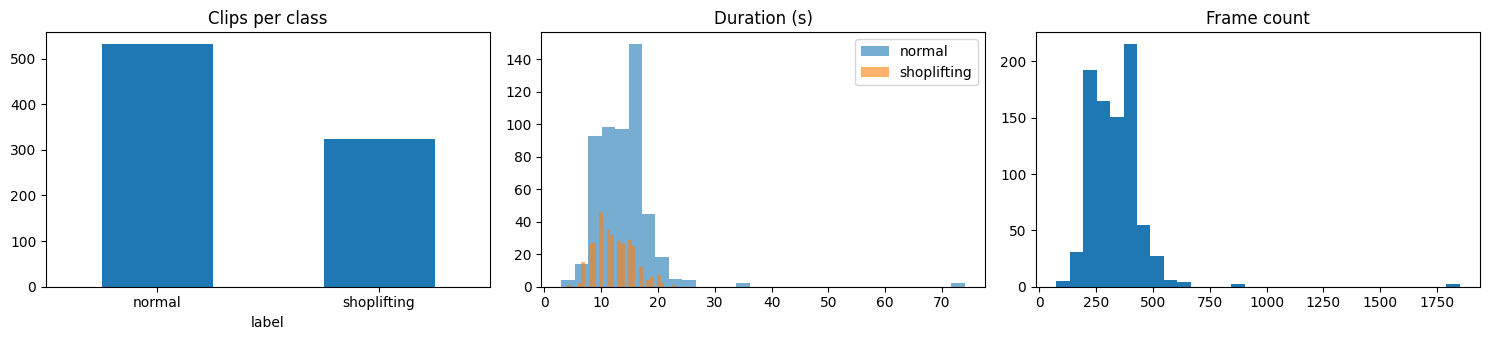

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
df.label.map({0: "normal", 1: "shoplifting"}).value_counts().plot.bar(ax=ax[0], rot=0, title="Clips per class")
for l, name in [(0, "normal"), (1, "shoplifting")]:
    ax[1].hist(df[df.label == l].duration, bins=30, alpha=0.6, label=name)
ax[1].set_title("Duration (s)"); ax[1].legend()
ax[2].hist(df.frames, bins=30); ax[2].set_title("Frame count")
plt.tight_layout(); plt.show()

## Frame sampling and cache

In [5]:
def sample_indices(n, T, train=False, rng=None):
    edges = np.linspace(0, n, T + 1)
    lo, hi = edges[:-1], edges[1:]
    pos = lo + (hi - lo) * rng.random(T) if train else (lo + hi) / 2
    return np.clip(pos.astype(int), 0, n - 1)

for n in (90, 300, 1000, 1850):
    idx = sample_indices(n, 16)
    print(n, idx.tolist(), "last segment starts at", int(n * 15 / 16))

90 [2, 8, 14, 19, 25, 30, 36, 42, 47, 53, 59, 64, 70, 75, 81, 87] last segment starts at 84
300 [9, 28, 46, 65, 84, 103, 121, 140, 159, 178, 196, 215, 234, 253, 271, 290] last segment starts at 281
1000 [31, 93, 156, 218, 281, 343, 406, 468, 531, 593, 656, 718, 781, 843, 906, 968] last segment starts at 937
1850 [57, 173, 289, 404, 520, 635, 751, 867, 982, 1098, 1214, 1329, 1445, 1560, 1676, 1792] last segment starts at 1734


In [6]:
def build_cache(path, out):
    if os.path.exists(out):
        return True
    cap = cv2.VideoCapture(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    idx = [int(i) for i in sample_indices(n, CACHE_N)]
    want, store, i = set(idx), {}, 0
    while i <= idx[-1]:
        if not cap.grab():
            break
        if i in want:
            ok, f = cap.retrieve()
            if ok:
                store[i] = cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2RGB), (IMG, IMG), interpolation=cv2.INTER_AREA)
        i += 1
    cap.release()
    if not store:
        return False
    keys = np.array(sorted(store))
    arr = np.stack([store[int(keys[np.abs(keys - j).argmin()])] for j in idx])
    np.save(out, arr)
    return True

df["cache"] = [f"{CACHE_DIR}/{i}.npy" for i in range(len(df))]
ok = Parallel(n_jobs=4)(delayed(build_cache)(p, c) for p, c in tqdm(zip(df.path, df.cache), total=len(df)))
df = df[np.array(ok)].reset_index(drop=True)
print(len(df), "clips cached")

  0%|          | 0/855 [00:00<?, ?it/s]

855 clips cached


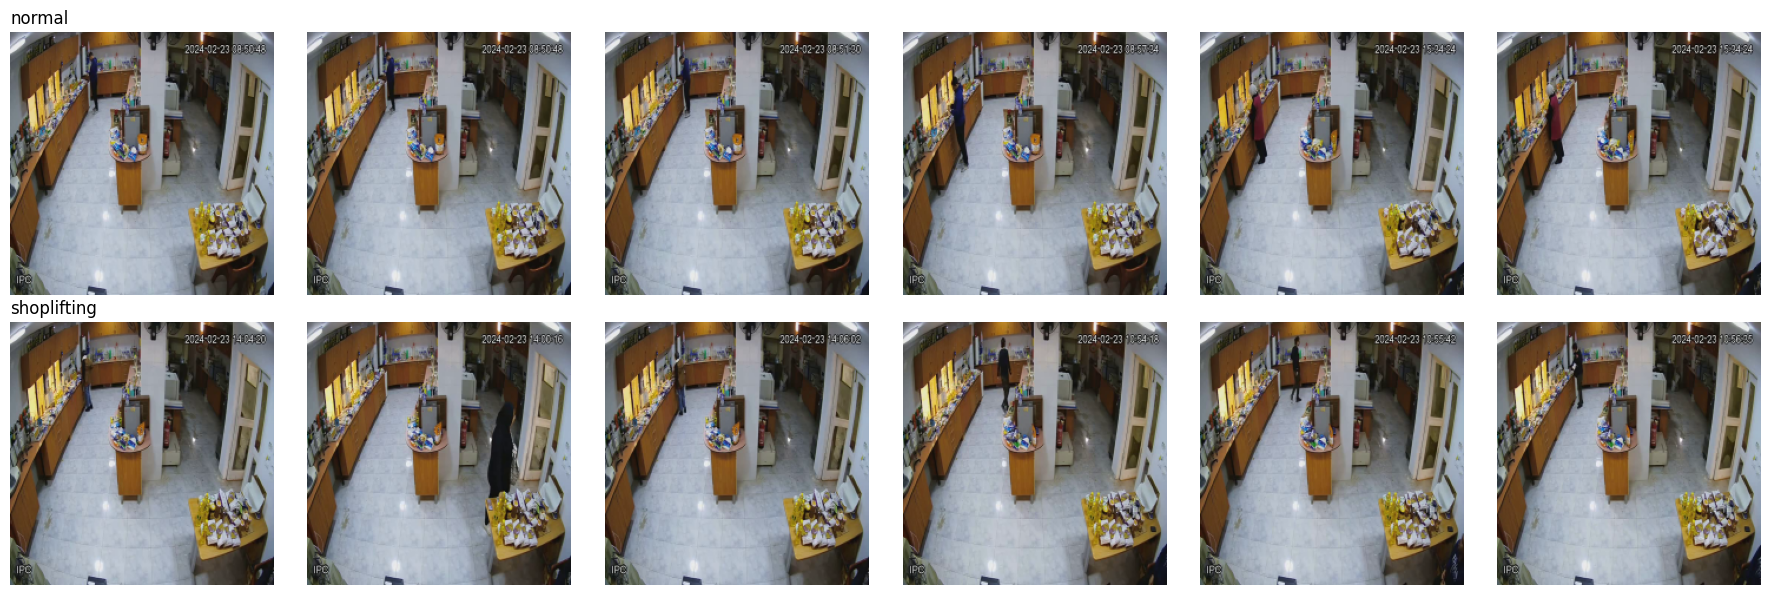

In [7]:
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for r, l in enumerate((0, 1)):
    for c, i in enumerate(df[df.label == l].index[:6]):
        ax[r, c].imshow(np.load(df.cache[i], mmap_mode="r")[CACHE_N // 2]); ax[r, c].axis("off")
    ax[r, 0].set_title("normal" if l == 0 else "shoplifting", loc="left")
plt.tight_layout(); plt.show()

## Duplicate removal and group-aware split
Near-duplicate clips are (1) **dropped** when almost identical (frame-by-frame), and (2) **grouped** when similar, so a group never straddles train/val/test.

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 214MB/s] 


  0%|          | 0/855 [00:00<?, ?it/s]

candidate pairs: 20800 of 365085
pairs >= GROUP_THR: 350 | >= DUP_THR: 218


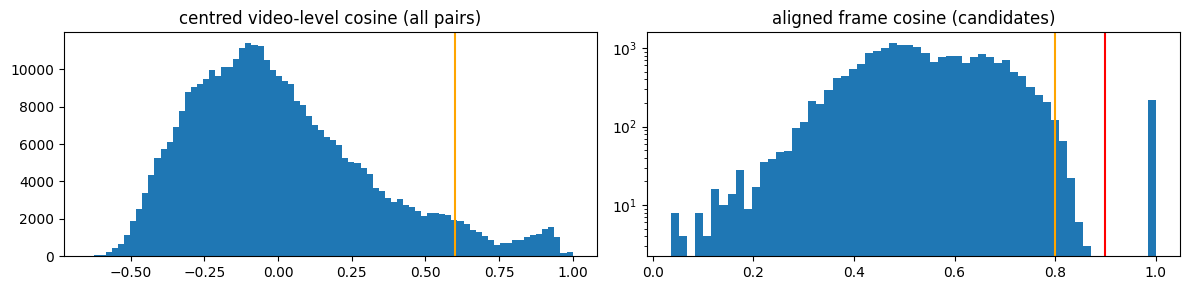

In [8]:
rn = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
rn.fc = nn.Identity()
rn = rn.to(device).eval()

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
EMB_IDX = np.linspace(0, CACHE_N - 1, 16).astype(int)      # 16 aligned frames per clip

@torch.no_grad()
def clip_frame_emb(cache_path):
    x = torch.from_numpy(np.load(cache_path, mmap_mode="r")[EMB_IDX].copy()).permute(0, 3, 1, 2).float() / 255
    x = ((x - MEAN) / STD).to(device)
    with torch.autocast("cuda", enabled=use_cuda):
        return rn(x).float().cpu().numpy()                 # (16, 2048)

femb = np.stack([clip_frame_emb(p) for p in tqdm(df.cache)])   # (N, 16, D)
del rn; torch.cuda.empty_cache()

# centre by the dataset mean: removes the shared camera/background component that makes every clip look alike
fc = femb - femb.reshape(-1, femb.shape[-1]).mean(0)
fc /= np.linalg.norm(fc, axis=-1, keepdims=True) + 1e-8
emb = fc.mean(1)
emb /= np.linalg.norm(emb, axis=1, keepdims=True) + 1e-8

def pair_scores(emb, fc, cand_thr):
    # candidates from averaged-embedding cosine, confirmed by mean aligned frame-by-frame cosine
    s = emb @ emb.T
    P = np.argwhere(np.triu(s >= cand_thr, 1))
    out = np.full(s.shape, -1.0, dtype=np.float32)
    for i in range(0, len(P), 256):
        a, b = P[i:i + 256].T
        out[a, b] = out[b, a] = (fc[a] * fc[b]).sum(-1).mean(1)
    return s, out

def clusters(s, thr):
    return connected_components(csr_matrix(s >= thr), directed=False)[1]

vsim, sim = pair_scores(emb, fc, CAND_THR)
upper = sim[np.triu_indices(len(sim), 1)]
upper = upper[upper > -1]
print("candidate pairs:", len(upper), "of", len(emb) * (len(emb) - 1) // 2)
print("pairs >= GROUP_THR:", int((upper >= GROUP_THR).sum()), "| >= DUP_THR:", int((upper >= DUP_THR).sum()))
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].hist(vsim[np.triu_indices(len(vsim), 1)], bins=80); ax[0].axvline(CAND_THR, c="orange")
ax[0].set_title("centred video-level cosine (all pairs)")
ax[1].hist(upper, bins=60); ax[1].set_yscale("log"); ax[1].set_title("aligned frame cosine (candidates)")
ax[1].axvline(GROUP_THR, c="orange"); ax[1].axvline(DUP_THR, c="r")
plt.tight_layout(); plt.show()

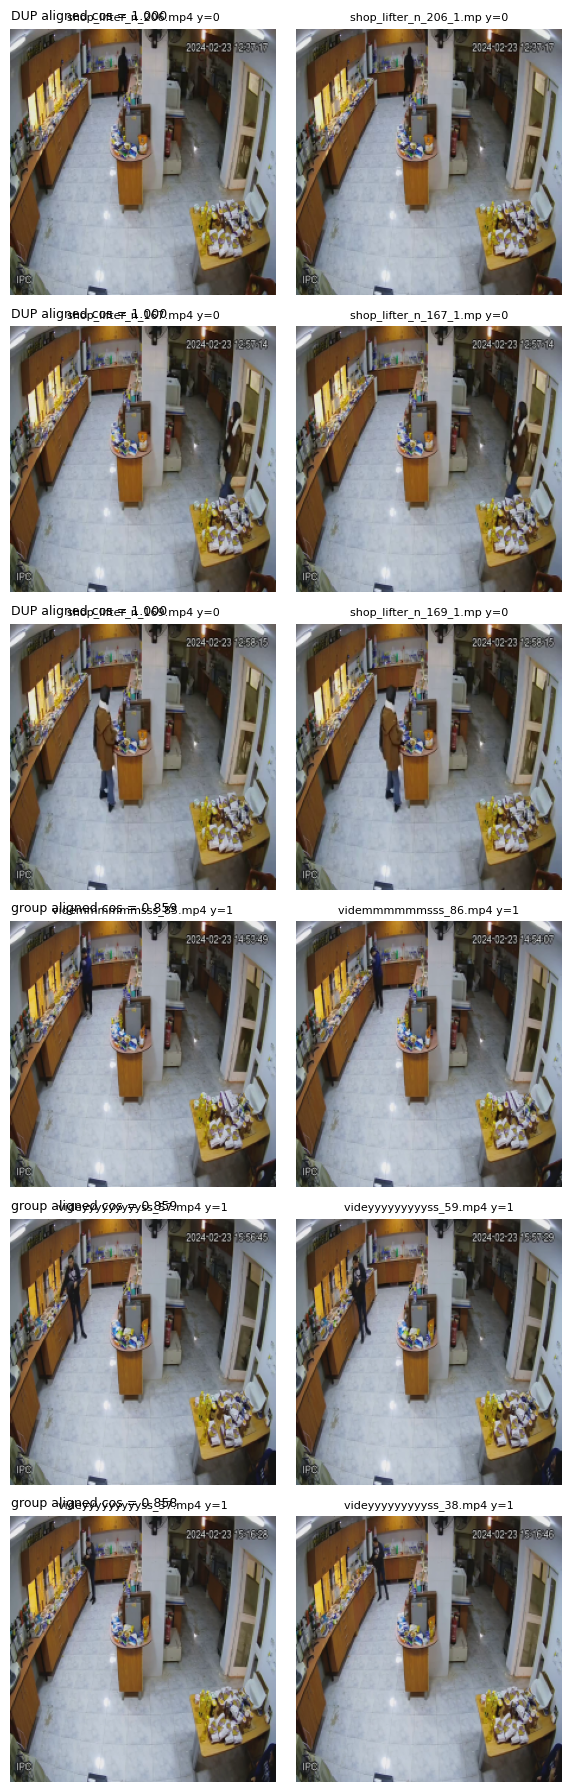

In [9]:
# Look at pairs just above and just below the thresholds before trusting them
iu = np.triu_indices(len(df), 1)
sc = sim[iu]
order = np.argsort(-sc)
above = [t for t in order if sc[t] >= DUP_THR][-3:]                      # weakest accepted duplicates
below = [t for t in order if GROUP_THR <= sc[t] < DUP_THR][:3]           # strongest rejected-as-duplicate (grouped only)
pairs = above + below
fig, ax = plt.subplots(max(len(pairs), 1), 2, figsize=(6, 3 * max(len(pairs), 1)), squeeze=False)
for r, t in enumerate(pairs):
    a, b = iu[0][t], iu[1][t]
    for c, j in enumerate((a, b)):
        ax[r, c].imshow(np.load(df.cache[j], mmap_mode="r")[CACHE_N // 2]); ax[r, c].axis("off")
        ax[r, c].set_title(f"{os.path.basename(df.path[j])[:22]} y={df.label[j]}", fontsize=8)
    ax[r, 0].text(0, -8, ("DUP " if sc[t] >= DUP_THR else "group ") + f"aligned cos = {sc[t]:.3f}", fontsize=9)
plt.tight_layout(); plt.show()

In [10]:
# 1) DROP duplicates (keep the first copy of each cluster)
n_before = len(df)
dup = clusters(sim, DUP_THR)
labels_all = df.label.values
conflict = pd.Series(labels_all).groupby(dup).nunique().gt(1)
print("duplicate clusters with conflicting labels:", int(conflict.sum()))
keep = np.sort(np.unique(dup, return_index=True)[1])
conf_ids = set(np.where(conflict)[0])
keep = np.array([k for k in keep if dup[k] not in conf_ids])          # conflicting-label clusters are ambiguous: drop entirely
dropped = n_before - len(keep)
print(f"DUPLICATES DROPPED: {dropped} of {n_before} clips ({dropped / n_before:.1%})")
assert dropped / n_before <= MAX_DROP, "too many drops: inspect the plots above and adjust DUP_THR / CAND_THR"

df = df.iloc[keep].reset_index(drop=True)
femb, fc, emb = femb[keep], fc[keep], emb[keep]
sim = sim[np.ix_(keep, keep)]

# 2) GROUP near-duplicates for the split
df["group"] = clusters(sim, GROUP_THR)
sizes = df.group.value_counts()
mixed = int((df.groupby("group").label.nunique() > 1).sum())
print(df.label.map({0: "normal", 1: "shoplifting"}).value_counts().to_string())
print("clips:", len(df), "| groups:", df.group.nunique(), "| largest group:", int(sizes.iloc[0]),
      "| clips in groups > 1:", int((df.group.map(sizes) > 1).sum()), "| mixed-label groups:", mixed)

duplicate clusters with conflicting labels: 0
DUPLICATES DROPPED: 218 of 855 clips (25.5%)
label
shoplifting    324
normal         313
clips: 637 | groups: 561 | largest group: 15 | clips in groups > 1: 96 | mixed-label groups: 0


In [11]:
# Shortcut check: can trivial clip statistics (no behaviour at all) predict the label?
def stats(p):
    a = np.load(p, mmap_mode="r")[:, ::4, ::4].astype(np.float32)
    return [np.abs(np.diff(a, axis=0)).mean(), a.mean(), a.std(axis=(1, 2, 3)).mean()]
S = np.array([stats(p) for p in tqdm(df.cache)])
X = np.column_stack([df.frames, df.fps, df.duration, S])
names_ = ["frames", "fps", "duration", "motion", "bright", "contrast"]
print({n: round(roc_auc_score(df.label, X[:, i]), 3) for i, n in enumerate(names_)})
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
pb = cross_val_predict(base, X, df.label.values, groups=df.group.values,
                       cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print("metadata-only baseline AUC (grouped CV):", round(roc_auc_score(df.label, pb), 3),
      "-> any model AUC should be judged against this, not against 0.5")

  0%|          | 0/637 [00:00<?, ?it/s]

{'frames': np.float64(0.381), 'fps': np.float64(0.435), 'duration': np.float64(0.382), 'motion': np.float64(0.481), 'bright': np.float64(0.604), 'contrast': np.float64(0.58)}
metadata-only baseline AUC (grouped CV): 0.705 -> any model AUC should be judged against this, not against 0.5


In [12]:
y, g = df.label.values, df.group.values
outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trval, test = next(outer.split(df, y, g))
inner = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_i, va_i = next(inner.split(df.iloc[trval], y[trval], g[trval]))

df["split"] = "train"
df.loc[test, "split"] = "test"
df.loc[trval[va_i], "split"] = "val"

print(pd.crosstab(df.split, df.label))
sg = df.groupby("group").split.nunique()
print("groups spanning several splits:", int((sg > 1).sum()))

# leakage audit: highest similarity between any two clips in different splits must stay below GROUP_THR
ix = {s: np.where(df.split == s)[0] for s in ("train", "val", "test")}
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    print(f"max cross-split similarity {a}/{b}:", round(float(sim[np.ix_(ix[a], ix[b])].max()), 4))
assert all(sim[np.ix_(ix[a], ix[b])].max() < GROUP_THR for a, b in (("train", "val"), ("train", "test"), ("val", "test")))

label    0    1
split          
test    37   40
train  234  244
val     42   40
groups spanning several splits: 0
max cross-split similarity train/val: 0.7997
max cross-split similarity train/test: 0.7994
max cross-split similarity val/test: 0.7798


## Augmentation and dataset

In [13]:
class ClipAug:
    def __call__(self, x):
        T, C, H, W = x.shape
        if random.random() < 0.5:
            x = x.flip(-1)
        scale, ratio = random.uniform(0.7, 1.0), random.uniform(3 / 4, 4 / 3)
        ch = int(min(H, round(H * math.sqrt(scale / ratio))))
        cw = int(min(W, round(W * math.sqrt(scale * ratio))))
        top, left = random.randint(0, H - ch), random.randint(0, W - cw)
        x = F.interpolate(x[:, :, top:top + ch, left:left + cw], size=(H, W), mode="bilinear", align_corners=False)
        b, c, s = random.uniform(0.75, 1.25), random.uniform(0.75, 1.25), random.uniform(0.7, 1.3)
        x = x * b
        m = x.mean()
        x = (x - m) * c + m
        gray = x.mean(1, keepdim=True)
        x = (x - gray) * s + gray
        return x.clamp(0, 1)

class ClipDataset(Dataset):
    def __init__(self, frame, T, train):
        self.cache, self.labels = frame.cache.tolist(), frame.label.tolist()
        self.T, self.train, self.aug = T, train, ClipAug()

    def __len__(self):
        return len(self.cache)

    def __getitem__(self, i):
        arr = np.load(self.cache[i], mmap_mode="r")
        rng = np.random.default_rng() if self.train else None
        idx = sample_indices(CACHE_N, self.T, self.train, rng)
        x = torch.from_numpy(np.ascontiguousarray(arr[idx])).permute(0, 3, 1, 2).float() / 255
        if self.train:
            x = self.aug(x)
        return (x - MEAN) / STD, self.labels[i]

In [14]:
frame = torch.rand(3, IMG, IMG).unsqueeze(0).repeat(16, 1, 1, 1)
out = ClipAug()(frame)
print("identical across frames:", all(torch.allclose(out[0], out[k]) for k in range(1, 16)))

x, y0 = ClipDataset(df[df.split == "train"], 16, True)[0]
xv, _ = ClipDataset(df[df.split == "val"], 16, False)[0]
print(x.shape, xv.shape)
assert x.shape == xv.shape == (16, 3, IMG, IMG)

identical across frames: True
torch.Size([16, 3, 224, 224]) torch.Size([16, 3, 224, 224])


## Pretrained model and training

In [15]:
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

def restore_qv_bias(model):
    try:
        sd = load_file(hf_hub_download(MODEL_NAME, "model.safetensors"))
    except Exception:
        sd = torch.load(hf_hub_download(MODEL_NAME, "pytorch_model.bin"), map_location="cpu")
    with torch.no_grad():
        for i, layer in enumerate(model.videomae.encoder.layer):
            a = layer.attention.attention
            a.query.bias.copy_(sd[f"videomae.encoder.layer.{i}.attention.attention.q_bias"])
            a.value.bias.copy_(sd[f"videomae.encoder.layer.{i}.attention.attention.v_bias"])
            a.key.bias.zero_()

def make_model(T):
    m = VideoMAEForVideoClassification.from_pretrained(
        MODEL_NAME, num_labels=2, num_frames=T, ignore_mismatched_sizes=True)
    restore_qv_bias(m)
    m.config.id2label = {0: "normal", 1: "shoplifting"}
    m.config.label2id = {"normal": 0, "shoplifting": 1}
    if T > 16:
        m.gradient_checkpointing_enable()
    return m

In [16]:
def metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred), f1=f1_score(y, pred), auc=roc_auc_score(y, p))

@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_cuda):
            p = model(pixel_values=x).logits.float().softmax(-1)[:, 1]
            if tta:
                p = (p + model(pixel_values=x.flip(-1)).logits.float().softmax(-1)[:, 1]) / 2
        P.append(p.cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def loader(split, T, train=False, bs=4):
    return DataLoader(ClipDataset(df[df.split == split], T, train), batch_size=bs, shuffle=train,
                      num_workers=2, drop_last=train, pin_memory=use_cuda)

def train(T, epochs, patience, verbose=True):
    bs = 4 if T <= 16 else 2
    accum = 8 // bs
    model = make_model(T).to(device)
    tr, va = loader("train", T, True, bs), loader("val", T)

    head = [p for n, p in model.named_parameters() if n.startswith(("classifier", "fc_norm"))]
    body = [p for n, p in model.named_parameters() if not n.startswith(("classifier", "fc_norm"))]
    opt = torch.optim.AdamW([{"params": body, "lr": LR_BODY}, {"params": head, "lr": LR_HEAD}], weight_decay=0.05)
    total = epochs * (len(tr) // accum)
    warm = max(1, int(0.1 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))

    cnt = df[df.split == "train"].label.value_counts().sort_index().values
    w = torch.tensor(cnt.sum() / (2 * cnt), dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)
    scaler = torch.cuda.amp.GradScaler(enabled=use_cuda)

    best, bad, best_state, hist = -1, 0, None, []
    for ep in range(epochs):
        model.train(); t0 = time.time(); run = 0
        for step, (x, y) in enumerate(tr):
            x, y = x.to(device, non_blocking=True), y.to(device)
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_cuda):
                loss = loss_fn(model(pixel_values=x).logits.float(), y) / accum
            scaler.scale(loss).backward()
            run += loss.item() * accum
            if (step + 1) % accum == 0:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update()
                opt.zero_grad(set_to_none=True); sched.step()
        p, yv = predict(model, va)
        mv = metrics(yv, p)
        hist.append(dict(epoch=ep + 1, loss=run / len(tr), val_f1=mv["f1"], val_auc=mv["auc"], sec=time.time() - t0))
        if verbose:
            print(hist[-1])
        score = mv["f1"] + 1e-3 * mv["auc"]
        if score > best:
            best, bad = score, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

## Frames per clip analysis

In [17]:
SWEEP_T = (8, 16)
T_FINAL = T_DEFAULT
if RUN_SWEEP:
    rows = []
    for T in SWEEP_T:
        m, h = train(T, SWEEP_EPOCHS, patience=99, verbose=False)
        p, yv = predict(m, loader("val", T))
        mv = metrics(yv, p)
        rows.append(dict(T=T, val_f1=mv["f1"], val_auc=mv["auc"], sec_per_epoch=h.sec.mean()))
        print(rows[-1])
        del m; torch.cuda.empty_cache()
    sweep = pd.DataFrame(rows)
    print(sweep.round(4))
    T_FINAL = int(sweep[sweep.val_f1 >= sweep.val_f1.max() - 1e-9].T.min())
print("T selected:", T_FINAL)

config.json:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `400`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/162 [00:00<?, ?it/s]

...

{'T': 8, 'val_f1': 0.8974358974358975, 'val_auc': np.float64(0.968452380952381), 'sec_per_epoch': np.float64(21.31709361076355)}


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `400`.


Loading weights:   0%|          | 0/162 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     |                                                                                         
---------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.key.bias   | MISSING    |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.value.bi

{'T': 16, 'val_f1': 0.8333333333333334, 'val_auc': np.float64(0.9851190476190474), 'sec_per_epoch': np.float64(48.652050614356995)}
    T  val_f1  val_auc  sec_per_epoch
0   8  0.8974   0.9685        21.3171
1  16  0.8333   0.9851        48.6521
T selected: 0


In [18]:
print(sweep.round(4))
T_FINAL = int(sweep.loc[sweep.val_f1 >= sweep.val_f1.max() - 1e-9, "T"].min())
print("T selected:", T_FINAL)

    T  val_f1  val_auc  sec_per_epoch
0   8  0.8974   0.9685        21.3171
1  16  0.8333   0.9851        48.6521
T selected: 8


## Final fine-tuning

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `400`.


Loading weights:   0%|          | 0/162 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     |                                                                                         
---------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.key.bias   | MISSING    |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.value.bi

{'epoch': 1, 'loss': 0.6709620133668435, 'val_f1': 0.6611570247933884, 'val_auc': np.float64(0.9654761904761905), 'sec': 23.349058628082275}
{'epoch': 2, 'loss': 0.5240351511400287, 'val_f1': 0.8333333333333334, 'val_auc': np.float64(0.9845238095238095), 'sec': 23.479223012924194}
{'epoch': 3, 'loss': 0.40322650530759024, 'val_f1': 0.975609756097561, 'val_auc': np.float64(0.9874999999999999), 'sec': 23.91612148284912}
{'epoch': 4, 'loss': 0.3631780948959479, 'val_f1': 0.975, 'val_auc': np.float64(0.9940476190476191), 'sec': 24.38450002670288}
{'epoch': 5, 'loss': 0.2978254165969977, 'val_f1': 0.9876543209876543, 'val_auc': np.float64(0.9982142857142857), 'sec': 24.129159450531006}
{'epoch': 6, 'loss': 0.26184124029984995, 'val_f1': 0.9876543209876543, 'val_auc': np.float64(0.9988095238095238), 'sec': 24.101295471191406}
{'epoch': 7, 'loss': 0.2450562785653507, 'val_f1': 0.975609756097561, 'val_auc': np.float64(1.0), 'sec': 24.001938343048096}
{'epoch': 8, 'loss': 0.25055876274068817, '

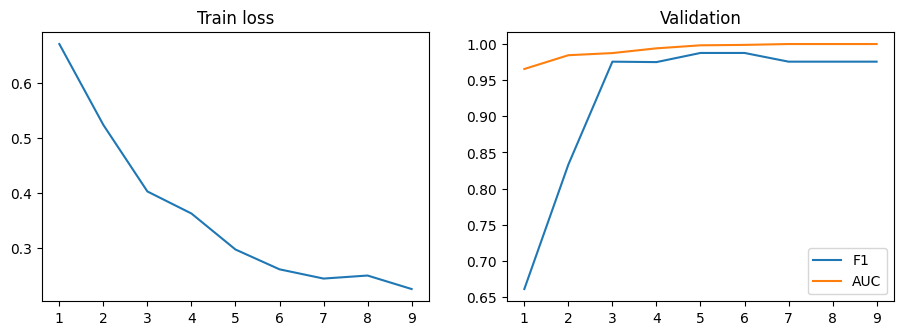

In [19]:
model, hist = train(T_FINAL, EPOCHS, PATIENCE)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist.epoch, hist.loss); ax[0].set_title("Train loss")
ax[1].plot(hist.epoch, hist.val_f1, label="F1"); ax[1].plot(hist.epoch, hist.val_auc, label="AUC")
ax[1].set_title("Validation"); ax[1].legend(); plt.show()

## Test evaluation

                      accuracy  precision  recall      f1     auc
threshold 0.50           0.974     0.9524   1.000  0.9756  0.9986
threshold 0.64 (val)     0.961     0.9512   0.975  0.9630  0.9986
test size: 77 | val size: 82
accuracy 95% Wilson CI: (0.892, 0.987)
group-bootstrap 95% CI: {'accuracy': (np.float64(0.909), np.float64(1.0)), 'f1': (np.float64(0.911), np.float64(1.0)), 'auc': (np.float64(0.994), np.float64(1.0))}


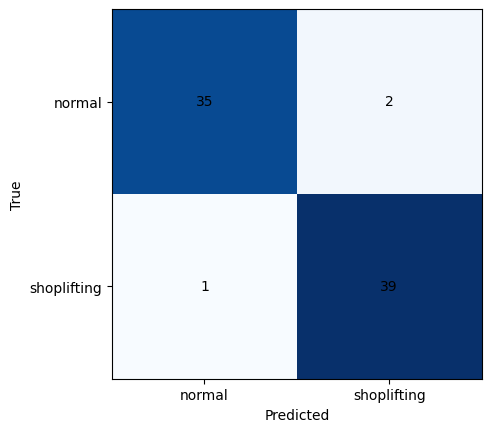

misclassified: 3
                                                                           path  label         p  pred
623  /kaggle/working/data/Shop DataSet/shop lifters/videyyyyyyzzzzzyyyss_19.mp4      1  0.591276     0
199     /kaggle/working/data/Shop DataSet/non shop lifters/shop_lifter_n_82.mp4      0  0.730909     1
206     /kaggle/working/data/Shop DataSet/non shop lifters/shop_lifter_n_89.mp4      0  0.806197     1
323          /kaggle/working/data/Shop DataSet/shop lifters/shop_lifter_107.mp4      1  0.899812     1
558        /kaggle/working/data/Shop DataSet/shop lifters/videyyyyyyyyyss_2.mp4      1  0.908931     1
343          /kaggle/working/data/Shop DataSet/shop lifters/shop_lifter_125.mp4      1  0.916716     1
548       /kaggle/working/data/Shop DataSet/shop lifters/videyyyyyyyyyss_10.mp4      1  0.921930     1
610        /kaggle/working/data/Shop DataSet/shop lifters/videyyyyyyyyyss_8.mp4      1  0.922784     1


In [20]:
def pick_thr(y, p):
    # threshold maximising F1; among tied thresholds take the middle one (argmax alone picks the lowest)
    grid = np.arange(0.05, 0.96, 0.01)
    f1s = np.array([f1_score(y, (p >= t).astype(int)) for t in grid])
    return float(np.median(grid[f1s >= f1s.max() - 1e-9]))

def wilson(k, n, z=1.96):
    ph = k / n; d = 1 + z * z / n
    c = (ph + z * z / (2 * n)) / d; h = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

def boot_ci(y, p, thr, B=2000, seed=0):
    # resample whole groups so near-duplicate clips are not counted as independent evidence
    rng = np.random.default_rng(seed)
    gt = df[df.split == "test"].group.values
    ug = np.unique(gt); idx_by = {u: np.where(gt == u)[0] for u in ug}
    out = {k: [] for k in ("accuracy", "f1", "auc")}
    for _ in range(B):
        ii = np.concatenate([idx_by[u] for u in rng.choice(ug, len(ug))])
        if len(np.unique(y[ii])) < 2: continue
        m = metrics(y[ii], p[ii], thr)
        for k in out: out[k].append(m[k])
    return {k: tuple(np.percentile(v, [2.5, 97.5]).round(3)) for k, v in out.items()}

pv, yv = predict(model, loader("val", T_FINAL), tta=True)
pt, yt = predict(model, loader("test", T_FINAL), tta=True)
thr = pick_thr(yv, pv)

res = pd.DataFrame({"threshold 0.50": metrics(yt, pt, 0.5), f"threshold {thr:.2f} (val)": metrics(yt, pt, thr)}).T
print(res.round(4))
print("test size:", len(yt), "| val size:", len(yv))
k = int(((pt >= thr).astype(int) == yt).sum())
print("accuracy 95% Wilson CI:", tuple(round(v, 3) for v in wilson(k, len(yt))))
print("group-bootstrap 95% CI:", boot_ci(yt, pt, thr))

cm = confusion_matrix(yt, (pt >= thr).astype(int))
plt.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    plt.text(j, i, v, ha="center", va="center")
plt.xticks([0, 1], ["normal", "shoplifting"]); plt.yticks([0, 1], ["normal", "shoplifting"])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

# error analysis: wrong and least-confident test clips
te = df[df.split == "test"].copy()
te["p"] = pt; te["pred"] = (pt >= thr).astype(int); te["margin"] = np.abs(pt - thr)
print("misclassified:", int((te.pred != te.label).sum()))
print(te.sort_values("margin").head(8)[["path", "label", "p", "pred"]].to_string())
if (te.pred == te.label).all():
    print("PERFECT TEST SCORE: treat as a warning sign, not a result (see the leakage audit and shortcut baseline above).")

### Grouped cross-validation
A single 118-clip test set is a noisy estimate. This repeats the whole recipe over folds that keep near-duplicate groups together.

In [21]:
if RUN_CV:
    base_split = df.split.copy()
    rows = []
    for f, (trv, te_) in enumerate(StratifiedGroupKFold(CV_FOLDS, shuffle=True, random_state=SEED).split(df, df.label, df.group)):
        tr2, va2 = next(StratifiedGroupKFold(6, shuffle=True, random_state=SEED).split(df.iloc[trv], df.label.values[trv], df.group.values[trv]))
        df["split"] = "train"; df.loc[te_, "split"] = "test"; df.loc[trv[va2], "split"] = "val"
        m, _ = train(T_FINAL, CV_EPOCHS, 2, verbose=False)
        pv_, yv_ = predict(m, loader("val", T_FINAL), tta=True)
        pt_, yt_ = predict(m, loader("test", T_FINAL), tta=True)
        rows.append(metrics(yt_, pt_, pick_thr(yv_, pv_))); print(f, rows[-1])
        del m; torch.cuda.empty_cache()
    df["split"] = base_split
    cvdf = pd.DataFrame(rows)
    print(cvdf.agg(["mean", "std"]).round(4))
else:
    print("RUN_CV = False: set it to True for grouped cross-validation (mean +/- std over folds).")

RUN_CV = False: set it to True for grouped cross-validation (mean +/- std over folds).


## Comparison with the Week 5 scratch model

In [22]:
@torch.no_grad()
def latency_ms(model, T, runs=30):
    model.eval()
    x = torch.randn(1, T, 3, IMG, IMG, device=device)
    with torch.autocast("cuda", dtype=torch.float16, enabled=use_cuda):
        for _ in range(5):
            model(pixel_values=x)
        if use_cuda: torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(runs):
            model(pixel_values=x)
        if use_cuda: torch.cuda.synchronize()
    return (time.time() - t0) / runs * 1000

params = sum(p.numel() for p in model.parameters())
lat = latency_ms(model, T_FINAL)

SCRATCH_LATENCY_MS = None
# NOTE: scratch numbers come from its own split (its own dedup/grouping), so the test sets differ. Re-run both on the same split for a fair comparison.
scratch_params = 3.27e6
scratch = {0.5: dict(accuracy=0.8780, precision=0.9348, recall=0.8600, f1=0.8958, auc=0.9681),
           0.27: dict(accuracy=0.8902, precision=0.8596, recall=0.9800, f1=0.9159, auc=0.9681)}
pre = {0.5: metrics(yt, pt, 0.5), round(thr, 2): metrics(yt, pt, thr)}

def row(name, n_params, latency, input_desc, m, t):
    return {"Model": name, "Threshold": round(float(t), 2), "Params (M)": round(n_params / 1e6, 2),
            "Size fp32 (MB)": round(n_params * 4 / 1e6, 1), "Input": input_desc,
            "Latency (ms/clip)": "n/a" if latency is None else round(latency, 1), **{k: round(v, 4) for k, v in m.items()}}

table = pd.DataFrame(
    [row("CNN + BiLSTM (scratch)", scratch_params, SCRATCH_LATENCY_MS, "16 x 112", m, t) for t, m in scratch.items()] +
    [row("VideoMAE-B (pretrained)", params, lat, f"{T_FINAL} x {IMG}", m, t) for t, m in pre.items()])
table.to_csv(f"{WORK}/comparison.csv", index=False)
table

,Model,Threshold,Params (M),Size fp32 (MB),Input,Latency (ms/clip),accuracy,precision,recall,f1,auc
0,CNN + BiLSTM (scratch),0.50,3.27,13.1,16 x 112,n/a,0.8780,0.9348,0.860,0.8958,0.9681
1,CNN + BiLSTM (scratch),0.27,3.27,13.1,16 x 112,n/a,0.8902,0.8596,0.980,0.9159,0.9681
2,VideoMAE-B (pretrained),0.50,86.24,345.0,8 x 224,15.3,0.9740,0.9524,1.000,0.9756,0.9986
3,VideoMAE-B (pretrained),0.64,86.24,345.0,8 x 224,15.3,0.9610,0.9512,0.975,0.9630,0.9986


In [23]:
d05 = pre[0.5]["f1"] - scratch[0.5]["f1"]
print(f"F1 at 0.5: pretrained {pre[0.5]['f1']:.4f} vs scratch {scratch[0.5]['f1']:.4f} (difference {d05:+.4f})")
if pre[0.5]["f1"] >= 0.995:
    print("A near-perfect score on a small test set is not evidence the model is solved. "
          "Check the leakage audit, the metadata-only baseline and the group-bootstrap CI before claiming it beats the scratch model.")
model.save_pretrained(f"{WORK}/videomae_shoplifting")

F1 at 0.5: pretrained 0.9756 vs scratch 0.8958 (difference +0.0798)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Trade-offs

Accuracy: Kinetics pretraining gives the backbone motion and body-part features that the scratch model has to learn from a few hundred clips. The reported test score is only trustworthy after duplicate removal, the leakage audit, and a check against the metadata-only baseline; report it with a confidence interval, not as a single number.

Data hygiene: near-identical clips are dropped (one copy kept) and similar clips are grouped so they never straddle splits. The number dropped is printed in the duplicate-removal section.

Size: VideoMAE-B has roughly 25 times more parameters than the scratch CNN + BiLSTM, which affects storage and memory.

Speed: each clip passes through a full ViT over 16 x 224 x 224 tokens, so inference is slower than the 112 x 112 scratch model. Fill `SCRATCH_LATENCY_MS` with a measurement of the scratch model on the same GPU for a direct comparison.

Frames per clip: the value of T was chosen from the validation sweep rather than fixed, and frames are sampled from equal temporal segments so the end of each video is always covered.